Estimar la biomasa en un bioreactor en el instante siguiente, a patir de la biomnasa y sustrato en el instante actual
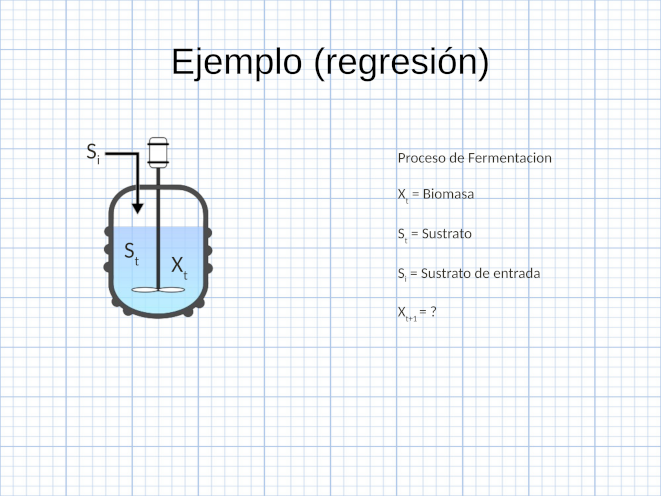


Primero, debemos importar los datos con pandas (desde un repositorio web)


In [ ]:
import pandas as pd
from sklearn import model_selection

dataset = pd.read_csv("http://posgrado.itlp.edu.mx/datasets/da-ex.csv",header=None)

X = dataset.values[:,0:2] #Columnnas 0 y 1 son las variables de entrada
y = dataset.values[:,2] #Columna 2 la biomasa en t+1


Normalización de las entradas por el método de máximo y mínimo

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaler.fit(X)

Z = scaler.transform(X)


Comparamos los diferentes modelos mediante k-folda y desplegamos los resultados

Method K-Nearest Neighbors.........: mean -0.002052 std(0.000488)
Method Desicion Tree Regressor.....: mean -0.002870 std(0.001293)
Method Support Vector Machine......: mean -0.004293 std(0.000328)
Method Multi Layer Perceptron......: mean -0.000251 std(0.000436)
Method Random Forrest Regressor....: mean -0.001321 std(0.000278)


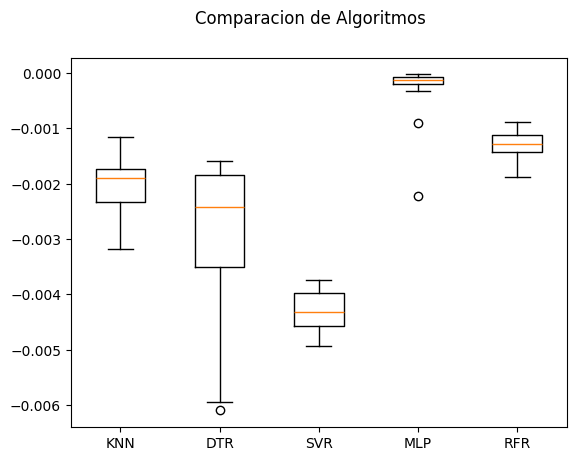

In [ ]:
import matplotlib.pyplot as plt
from sklearn import model_selection

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

scoring = 'neg_mean_squared_error'
names = ["KNN", "DTR", "SVR", "MLP","RFR"]

models = [('K-Nearest Neighbors.........', KNeighborsRegressor(n_neighbors=10)),
          ('Desicion Tree Regressor.....', DecisionTreeRegressor()),
          ('Support Vector Machine......', SVR()),
          ('Multi Layer Perceptron......',MLPRegressor(solver='lbfgs',
                                                       hidden_layer_sizes=(50), max_iter=10000)),
          ('Random Forrest Regressor....',RandomForestRegressor())]

results = []


for name, model in models:
    kfold = model_selection.RepeatedKFold(n_splits=5, n_repeats=5)
    cv_results = model_selection.cross_val_score(model, Z, y, cv=kfold, scoring=scoring)
    results.append(cv_results)
    msg = "Method %s: mean %f std(%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

fig = plt.figure()
fig.suptitle('Comparacion de Algoritmos')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
plt.show()

Entrenamos el MLP, evaluamos su desempeño y desplegamos las métricas correspondientes a los diferentes conjuntos de datos

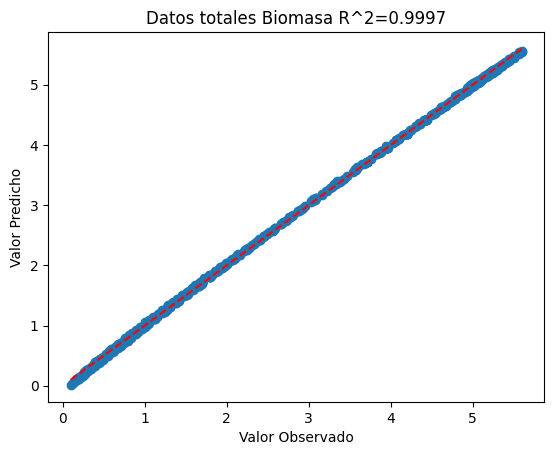

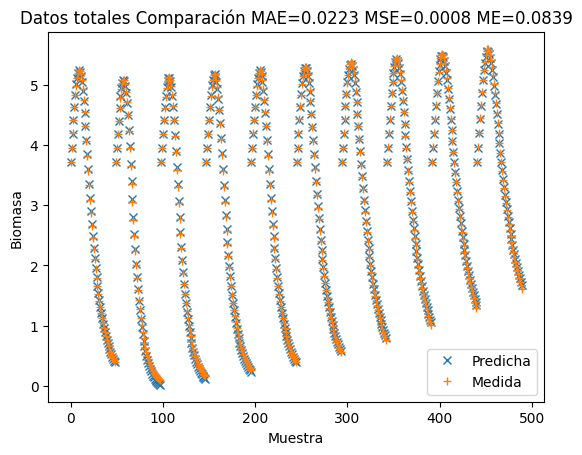

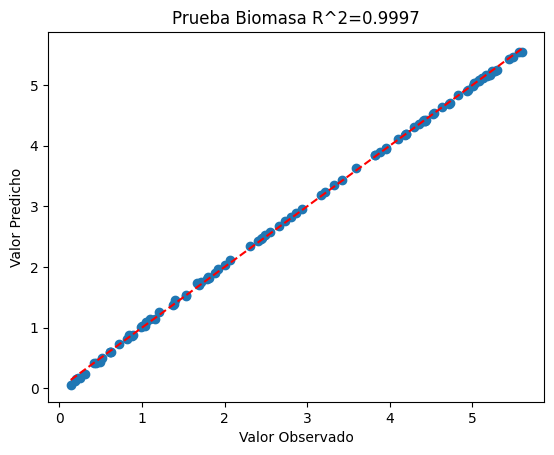

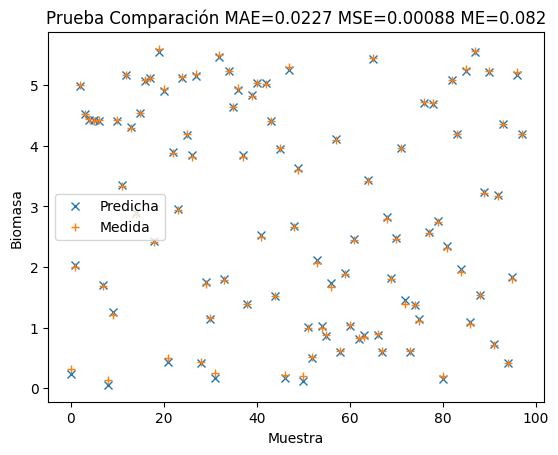

In [ ]:
from sklearn import metrics

###############################################
def evalua(x,y,titulo):
  predicted = best_model.predict(x)
  r2=metrics.r2_score(y,predicted)
  plt.title(titulo+" Biomasa R^2="+str(round(r2,4)))
  plt.ylabel("Valor Predicho")
  plt.xlabel("Valor Observado")
  plt.scatter(y,predicted)
  lineStart = y.min()
  lineEnd = y.max()
  plt.plot([lineStart, lineEnd], [lineStart, lineEnd], color = 'r', linestyle='dashed')
  plt.show()

  mse=metrics.mean_squared_error(y,predicted)
  mae=metrics.mean_absolute_error(y,predicted)
  me=metrics.max_error(y,predicted)
  plt.title(titulo+" Comparación MAE="+str(round(mae,4))+" MSE="+str(round(mse,5)) + " ME=" +str(round(me,4)))
  plt.plot(predicted,'x',label="Predicha")
  plt.plot(y,'+',label="Medida")
  plt.xlabel("Muestra")
  plt.ylabel("Biomasa")
  plt.legend()
  plt.show()
###############################################

Z_train, Z_test, y_train, y_test = model_selection.train_test_split(Z,y, test_size=0.20)

best_model=MLPRegressor(solver='lbfgs', hidden_layer_sizes=10, max_iter=10000)
best_model.fit(Z_train,y_train) #Entrenamiento del modelo

evalua(Z,y,"Datos totales")
#evalua(Z_train,y_train,"Entrenamiento")
evalua(Z_test,y_test,"Prueba")